#Exploratory Data Analysis - EDA
--------------------------------------------------------------------------------
--------------------------------------------------------------------------------

##Import Files, Load Data

In [2]:
from google.colab import files
upload=files.upload()

Saving sb_utils.py to sb_utils.py


In [3]:
from sb_utils import save_file
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [4]:
nyc_data_analysis=pd.read_csv('/content/nyc_data_cleaned.csv')
nyc_data_analysis.head(5)

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.210000,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.380000,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,1.373221,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.640000,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.100000,1,0


In [5]:
nyc_data_analysis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [14]:
nyc_data_analysis.shape
print('The data has', nyc_data_analysis.shape[0], 'rows and', nyc_data_analysis.shape[1], 'columns')

The data has 48895 rows and 16 columns


In [15]:
nyc_data_analysis.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.497775,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.280000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,1.220000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,1.580000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [18]:
nyc_data_analysis.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

##Null Values

In [19]:
nyc_data_analysis.isna().sum()

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                     0
calculated_host_listings_count        0
availability_365                      0
dtype: int64

Name, host_name and last_review has missing values. Which means 20% reviews are missing. That could be because alot of customer don't give reviews when the service is satisfactory in terms of price of the room, location, availability, cleanliness etc.

##Drop Null Columns

In [ ]:
#nyc_data_analysis.drop(['id', 'name', 'host_id', 'host_name', 'latitude', 'longitude'], axis=1, inplace=True)
nyc_data_analysis.drop(['id', 'name', 'host_id', 'host_name'], axis=1, inplace=True)

In [ ]:
nyc_data_analysis.isna().sum()

neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                     0
calculated_host_listings_count        0
availability_365                      0
dtype: int64

##Fill Null Values

Lets fill out the missing values with zeros

In [20]:
nyc_data_analysis.fillna('0', inplace=True)

In [28]:
nyc_data_analysis.isna().sum()

id                                0
name                              0
host_id                           0
host_name                         0
neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
last_review                       0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64

##Most Listings in each Neighbourhood

In [29]:
#Neighbourhood have the most listings
nyc_data_analysis['neighbourhood'].value_counts()

Williamsburg          3920
Bedford-Stuyvesant    3714
Harlem                2658
Bushwick              2465
Upper West Side       1971
                      ... 
Fort Wadsworth           1
Richmondtown             1
New Dorp                 1
Rossville                1
Willowbrook              1
Name: neighbourhood, Length: 221, dtype: int64

In [30]:
testing = nyc_data_analysis['neighbourhood']
testing1 = nyc_data_analysis.sort_values(['neighbourhood'], ascending = False)
testing1.max()
#testing1.count()

id                                                                    36487245
name                              ﾏﾝﾊｯﾀﾝ､駅から徒歩4分でどこに行くのにも便利な場所!女性の方希望,ｷﾚｲなお部屋｡
host_id                                                              274321313
host_name                                                                   현선
neighbourhood_group                                              Staten Island
neighbourhood                                                         Woodside
latitude                                                              40.91306
longitude                                                            -73.71299
room_type                                                          Shared room
price                                                                    10000
minimum_nights                                                            1250
number_of_reviews                                                          629
last_review                                         

Text(0.5, 1.0, 'Neighbourhood')

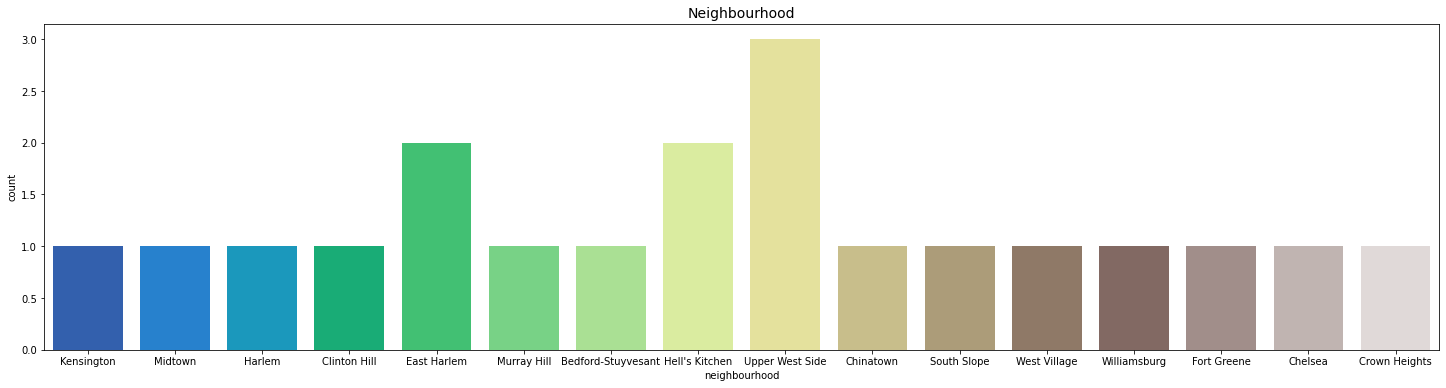

In [33]:
#Suppress future warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import pandas

sns.countplot(nyc_data_analysis['neighbourhood'].head(20), palette="terrain")
fig = plt.gcf()
fig.set_size_inches(25,6)
plt.title('Neighbourhood', size = 14)

Seaborn Barplot of the Neighbourhood shows the top 20 locations in New York area. Upper west side has the highest number of AirBnb units followed by Hell's kitchen and East harlem.

##Most Listings in each Neighbourhood Group

In [34]:
#Neighbourhood group have the most listings
nyc_data_analysis['neighbourhood_group'].value_counts()

Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373
Name: neighbourhood_group, dtype: int64

Text(0.5, 1.0, 'Neighbourhood Group')

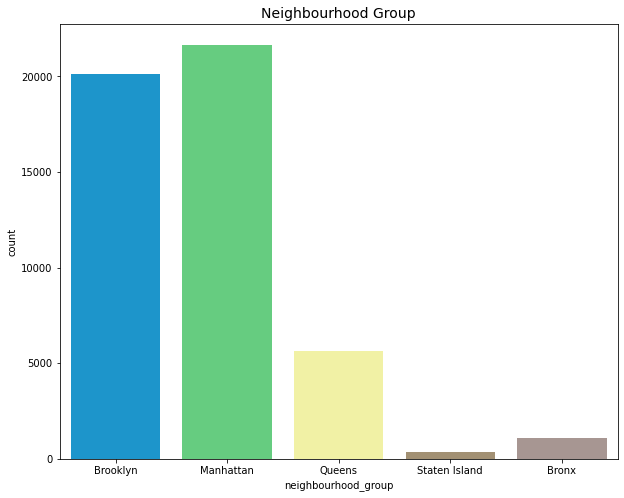

In [35]:
sns.countplot(nyc_data_analysis['neighbourhood_group'], palette="terrain")
fig = plt.gcf()
fig.set_size_inches(10,8)
plt.title('Neighbourhood Group', size = 14)

The above plot shows comparison among different neighbouhood groups in New York area with Manhattan has the most listed AirBnb units, Brooklyn comes close with total listed units are just above 20k.

##Number of Room Types

In [36]:
nyc_data_analysis['room_type'].value_counts()

Entire home/apt    25409
Private room       22326
Shared room         1160
Name: room_type, dtype: int64

In [37]:
nyc_data_analysis.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.497775,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.280000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,1.220000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,1.580000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


##Unique Values

In [38]:
#examining the unique values
nyc_data_analysis.neighbourhood_group.unique()

array(['Brooklyn', 'Manhattan', 'Queens', 'Staten Island', 'Bronx'],
      dtype=object)

##Neighbourhood Group

In [39]:
#Neighbourhood group have the most listings
top_host_listing=nyc_data_analysis.neighbourhood_group.value_counts()
top_host_listing

Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373
Name: neighbourhood_group, dtype: int64

In [40]:
#Neighbourhood have the most listings
top_host_listing=nyc_data_analysis.neighbourhood.value_counts()
top_host_listing

Williamsburg          3920
Bedford-Stuyvesant    3714
Harlem                2658
Bushwick              2465
Upper West Side       1971
                      ... 
Fort Wadsworth           1
Richmondtown             1
New Dorp                 1
Rossville                1
Willowbrook              1
Name: neighbourhood, Length: 221, dtype: int64

##Average Price per Unit

In [42]:
import numpy as np
mean_prices = np.mean(nyc_data_analysis.price)
mean_prices

152.7206871868289

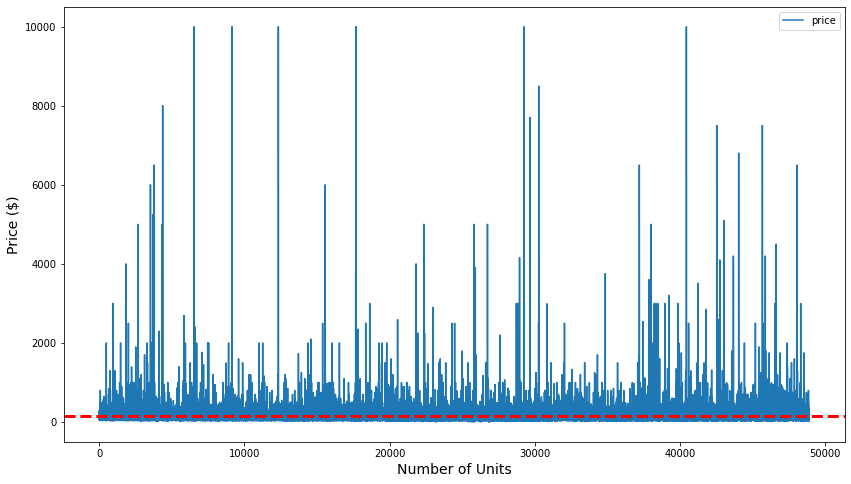

In [43]:
nyc_data_analysis.plot(y='price', legend = True, figsize=(14,8))
plt.ylabel('Price ($)', size = 14)
plt.xlabel('Number of Units', size = 14)
plt.axhline(np.nanmean(nyc_data_analysis.price), color='red', linestyle='--', linewidth=3, label='Avg')

Here, the average price per unit is $152. The red dotted line above shows the mean price.

##Average Price per Unit Type

Text(0.5, 0, 'Room Type')

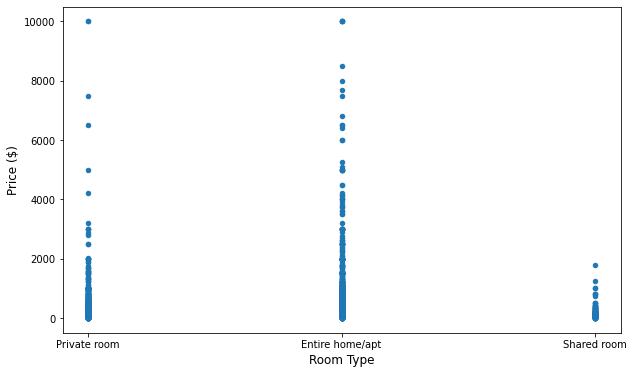

In [45]:
nyc_data_analysis.plot.scatter(x='room_type', y='price', figsize=(10,6))
plt.ylabel('Price ($)', size = 12)
plt.xlabel('Room Type', size = 12)

Text(0.5, 1.0, 'Room Type')

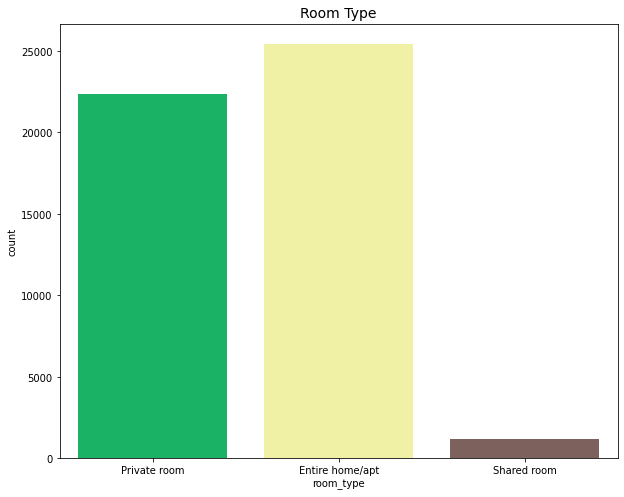

In [46]:
sns.countplot(nyc_data_analysis['room_type'], palette="terrain")
fig = plt.gcf()
fig.set_size_inches(10,8)
plt.title('Room Type', size = 14)

One thing to note here, shared room has the lowest prices in the New York area, with average prices are under 500. Most of the private room and entire home and apartment ranges from 500 to 2000 per night, depending on the location.

##Analysis for Unit Price < $500
Since most of the units are around 500 dollars, so let's plot each unit on the geographical map.

In [47]:
unit_under_500 = nyc_data_analysis[nyc_data_analysis.price < 500]

##Unit Geographical Location

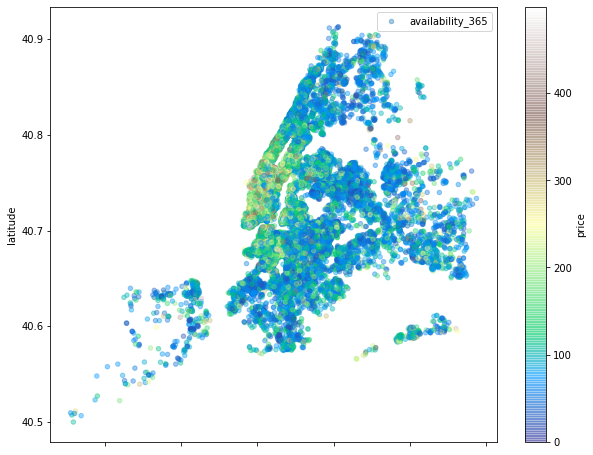

In [48]:
location_plot=unit_under_500.plot(kind='scatter', x='longitude', y='latitude', c='price', label='availability_365', 
                  cmap=plt.get_cmap('terrain'), colorbar=True, alpha=0.4, figsize=(10,8))
location_plot.legend()

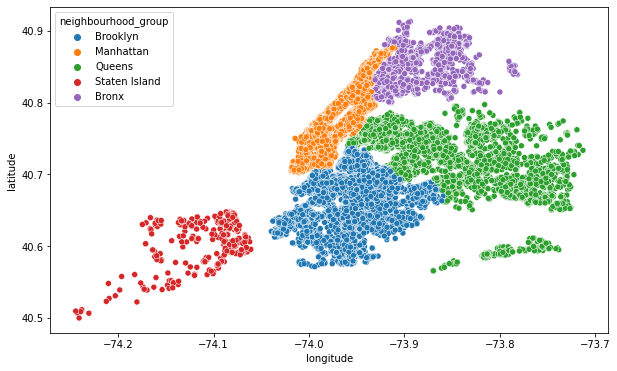

In [49]:
plt.figure(figsize=(10,6))
sns.scatterplot(nyc_data_analysis.longitude, nyc_data_analysis.latitude, hue=nyc_data_analysis.neighbourhood_group)
plt.ioff() #turn interactive mode off, doesn't accept any parameter
#plt.show()

##Unit Geographical Location on the Map

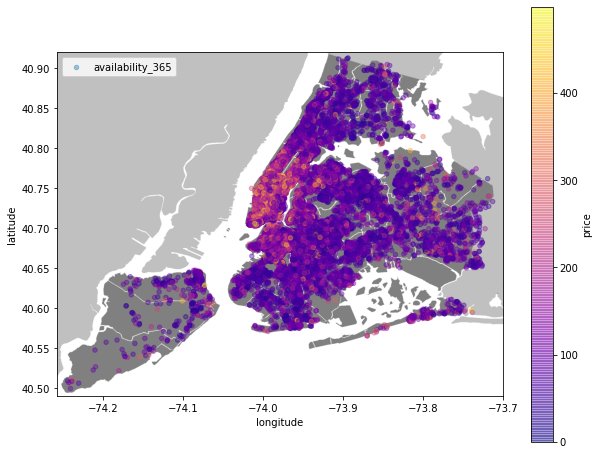

In [50]:
import urllib

plt.figure(figsize=(10,8))
#loading the NYC image found on Google
i = urllib.request.urlopen('https://upload.wikimedia.org/wikipedia/commons/e/ec/Neighbourhoods_New_York_City_Map.PNG')
nyc_img=plt.imread(i)
#latitude and longitude max and mins
plt.imshow(nyc_img,zorder=0,extent=[-74.258, -73.7, 40.49,40.92])
ax=plt.gca()

unit_under_500.plot(kind='scatter', x='longitude', y='latitude', label='availability_365', c='price', ax=ax, 
           cmap=plt.get_cmap('plasma'), colorbar=True, alpha=0.4, zorder=5)

plt.legend()
plt.show()

##Room Type

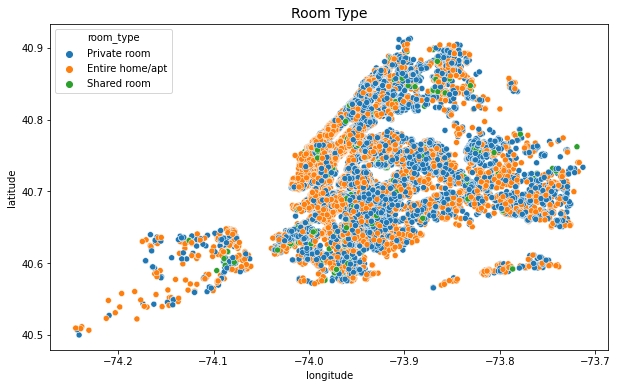

In [51]:
plt.figure(figsize = (10,6))
sns.scatterplot(nyc_data_analysis.longitude, nyc_data_analysis.latitude, hue = nyc_data_analysis.room_type)
plt.title('Room Type', size = 14)
plt.ioff()

##Room Availability

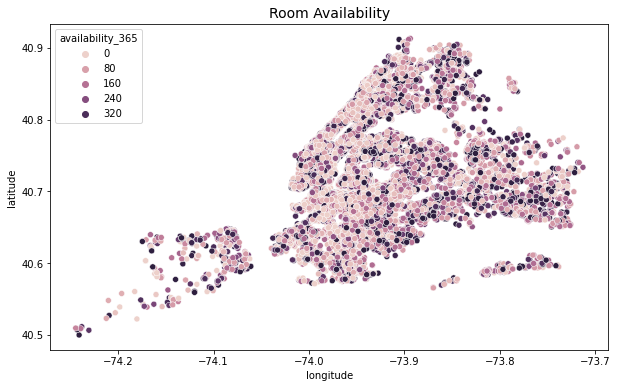

In [55]:
plt.figure(figsize=(10,6))
sns.scatterplot(nyc_data_analysis.longitude, nyc_data_analysis.latitude, hue=nyc_data_analysis.availability_365)
plt.title('Room Availability', size = 14)
#plt.show()
plt.ioff()  #to turn the interactive mode off

The plot above shows room availability which are available mostly throught the year as New York is one of the favourite tourist destination

##Neighbourhood Group Availability

Text(0.5, 1.0, 'Neighbourhood Group Availability')

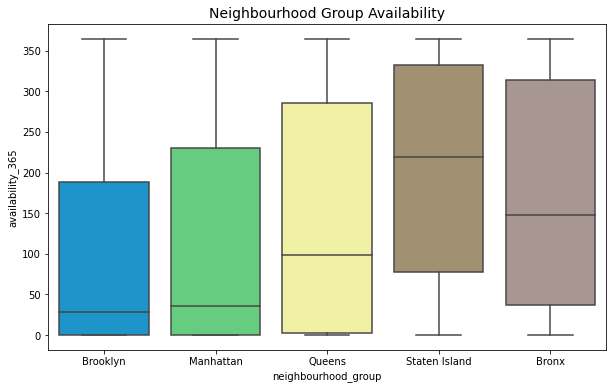

In [56]:
plt.figure(figsize=(10,6))
ax = sns.boxplot(data=nyc_data_analysis, x='neighbourhood_group', y='availability_365', palette='terrain')
plt.title('Neighbourhood Group Availability', size = 14)

Staten Island is among the top neighbourhood group. We can also interpret this as the most favorite tourist destination with the highest percentile of room availibity throught the year

##Neighbourhood Group Word Cloud

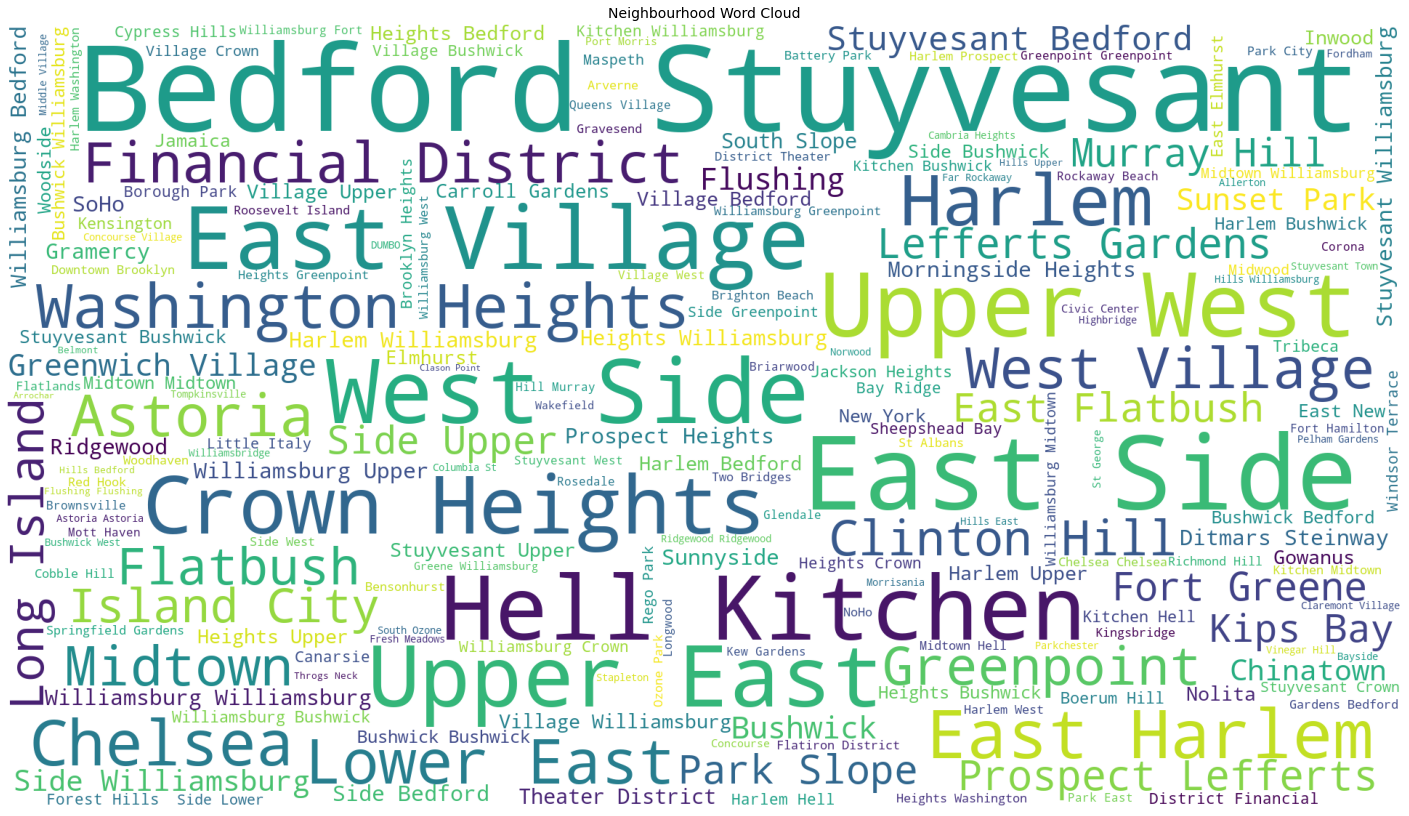

In [58]:
from wordcloud import WordCloud
plt.subplots(figsize=(25,15))
wordcloud = WordCloud(background_color='white', width=1920, height=1080).generate(" ".join(nyc_data_analysis.neighbourhood))
plt.imshow(wordcloud)
plt.axis('off')
plt.title('Neighbourhood Word Cloud', size = 14)
plt.show()

Word cloud used to visualize text data which the font size of each show the frequency, importance and prominance. Hell Kitchen, East side, west side, Bedford, Stuyvesant are the most frequent areas.

##Percentage of Room Distribution in each Neighbourhood Group

Let's look at the percentage of room distribution using plotly interactive pie plots for the neighbourhood group

In [59]:

import plotly.io as pio
pio.renderers

#import chart_studio.plotly as py
#py.iplot(fig)

Renderers configuration
-----------------------
    Default renderer: 'colab'
    Available renderers:
        ['plotly_mimetype', 'jupyterlab', 'nteract', 'vscode',
         'notebook', 'notebook_connected', 'kaggle', 'azure', 'colab',
         'cocalc', 'databricks', 'json', 'png', 'jpeg', 'jpg', 'svg',
         'pdf', 'browser', 'firefox', 'chrome', 'chromium', 'iframe',
         'iframe_connected', 'sphinx_gallery', 'sphinx_gallery_png']

In [60]:
import plotly.express as px
#import plotly.graph_objects as go
#from plotly.subplots import make_subplots

for group in nyc_data_analysis['neighbourhood_group'].unique():
    # Select data of a particular group/category
    data = nyc_data_analysis[nyc_data_analysis['neighbourhood_group']==group]
    
    title = f"Distribution Of Room Type In {group} Neighbourhood"
    fig = px.pie(data,names='room_type',hole=0.75,title=title)
    fig.show()
    plt.savefig('percentage plot') 

<Figure size 432x288 with 0 Axes>

From the above plots, we can conclude that private rooms has the highest percentage in every neighbourhood group with over 50% each. Shared rooms has the lowest.

In [ ]:
import os

if not os.path.exists("images"):
    os.mkdir("images")

In [ ]:
fig.write_image("images/fig1.jpeg")

##Continous Variable Relationship with the Price (target variable)

**Target variable (Price) is one the prime feature among others.** Let's compare it with other main features **(minimum_nights, number_of_reviews reviews_per_month, calculated_host_listings_count, availability_365**) in our data by visualizing it through parallel coordinate plot. Each feature corresponds to a vertical axis value/element and is displayed as a series of connected points 

In [61]:
def parallel_coordinate(nyc_data_analysis,target,con_cols):
    fig = px.parallel_coordinates(nyc_data_analysis, color=target,dimensions=con_cols,color_continuous_scale=px.colors.diverging.Tealrose, color_continuous_midpoint=2)
    return fig

In [62]:
fig = parallel_coordinate(nyc_data_analysis,'price',['minimum_nights','number_of_reviews','reviews_per_month','calculated_host_listings_count', 'availability_365'])
fig.show()

Parallel coordinate plot shows a nice overview of comparision among the different features. Too much overlapping can be done by scaling the axis because plot is based on interpolation (linear combination).

When most lines between two parallel axes are somewhat parallel, it suggests a **positive relationship** between these two features. 

When lines cross like X-shapes, it's a **negative relationship**. 

When lines cross randomly or are parallel, it shows there is **no particular relationship**.

##Correlation Matrix shows Positive and Negative Relationship between Different Variables

In [65]:
def plotCorrelationMatrix(nyc_data_analysis, graphWidth):
   
    filename = nyc_data_analysis
    df = nyc_data_analysis.dropna('columns') # drop columns with NaN
    df = nyc_data_analysis[[col for col in nyc_data_analysis if df[col].nunique() > 1]] # keep columns where there are more than 1 unique values
    if nyc_data_analysis.shape[1] < 2:
        print(f'No correlation plots shown: The number of non-NaN or constant columns ({nyc_data_analysis.shape[1]}) is less than 2')
        return
    corr = nyc_data_analysis.corr()
    plt.figure(num=None, figsize=(graphWidth, graphWidth), dpi=80, facecolor='w', edgecolor='k')
    corrMat = plt.matshow(corr, fignum = 1)
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
    plt.yticks(range(len(corr.columns)), corr.columns)
    plt.gca().xaxis.tick_bottom()
    plt.colorbar(corrMat)
  
    plt.title('Correlation Matrix Plot',size = 16)
    plt.show()

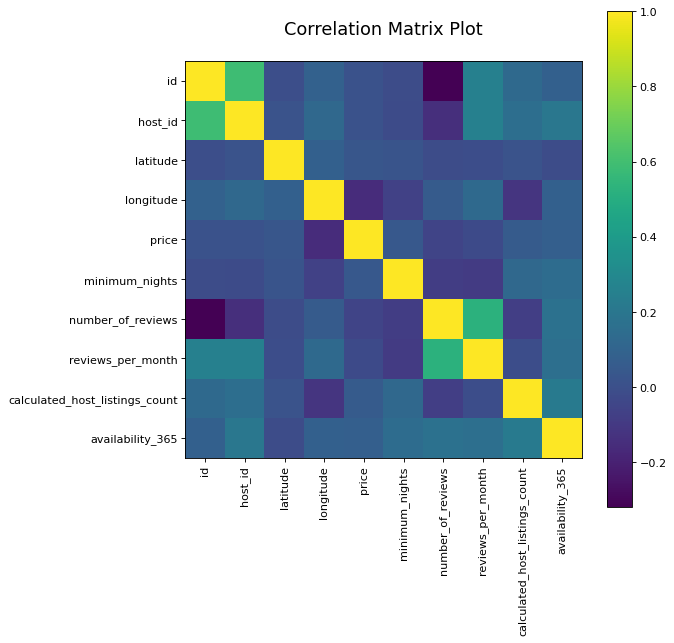

In [66]:
plotCorrelationMatrix(nyc_data_analysis,8);

##Correlation Matrix with Kendall Rank Correlation Coefficent Method

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

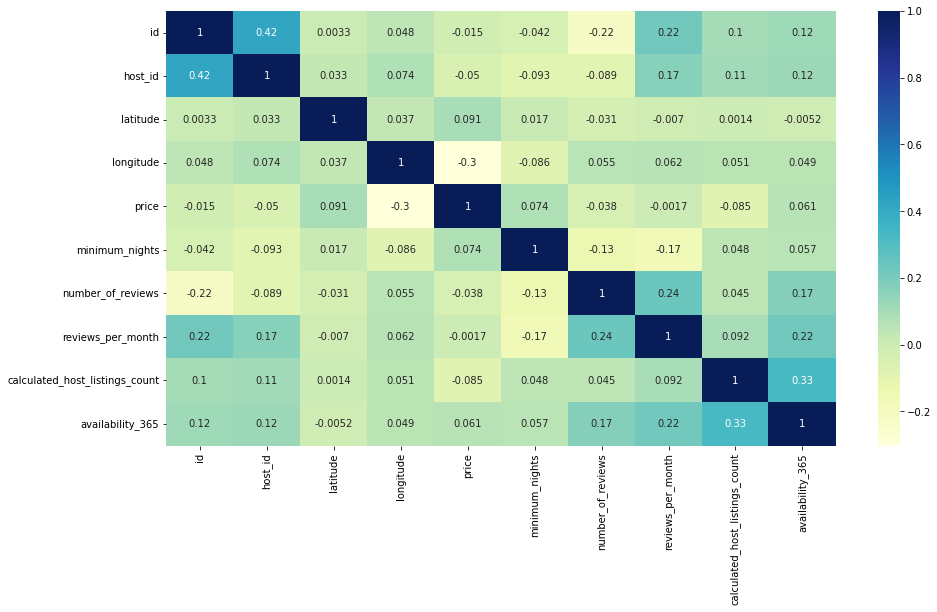

In [70]:
corr = nyc_data_analysis.corr(method='kendall')
plt.figure(figsize=(15,8))
sns.heatmap(corr, cmap="YlGnBu", annot=True)
nyc_data_analysis.columns

The correlation matrix heatmap plot shows the 2D correlation matrix among different features with a color palette showing the variation. We use the Kendell method here to find the similarities and measures of correspondence. 

**1 indicates strong agreement, and -1 indicates strong disagreement**

From the correlations heatmap diagram, we can see that price is strongly correlated with the number of accommodations, location, number of nights, and reviews. We also see that these features are correlated. These results are quite obvious because the price depends on the location of the place.

##Scatter Matrix Plot between Different Variables shows how multiple variables are related

In [71]:
import numpy as np

In [72]:
def plotScatterMatrix(nyc_data_analysis, plotSize, textSize):
    df = nyc_data_analysis.select_dtypes(include =[np.number]) # keep only numerical columns
    # Remove rows and columns that are null
    df = nyc_data_analysis.dropna('columns')
    df = nyc_data_analysis[[col for col in nyc_data_analysis if df[col].nunique() > 1]] # keep columns where there are more than 1 unique values
    columnNames = list(nyc_data_analysis)
    if len(columnNames) > 10: # reduce the number of columns for matrix inversion
        columnNames = columnNames[:10]
    df = nyc_data_analysis[columnNames]
    ax = pd.plotting.scatter_matrix(nyc_data_analysis, alpha=0.75, figsize=[plotSize, plotSize], diagonal='kde')
    corrs = nyc_data_analysis.corr().values
    for i, j in zip(*plt.np.triu_indices_from(ax, k = 1)):
        ax[i, j].annotate('Corr. coef = %.3f' % corrs[i, j], (0.8, 0.2), xycoords='axes fraction', ha='center', va='center', size=textSize)
    plt.suptitle('Scatter and Density Plot', size = 16)
    plt.show()

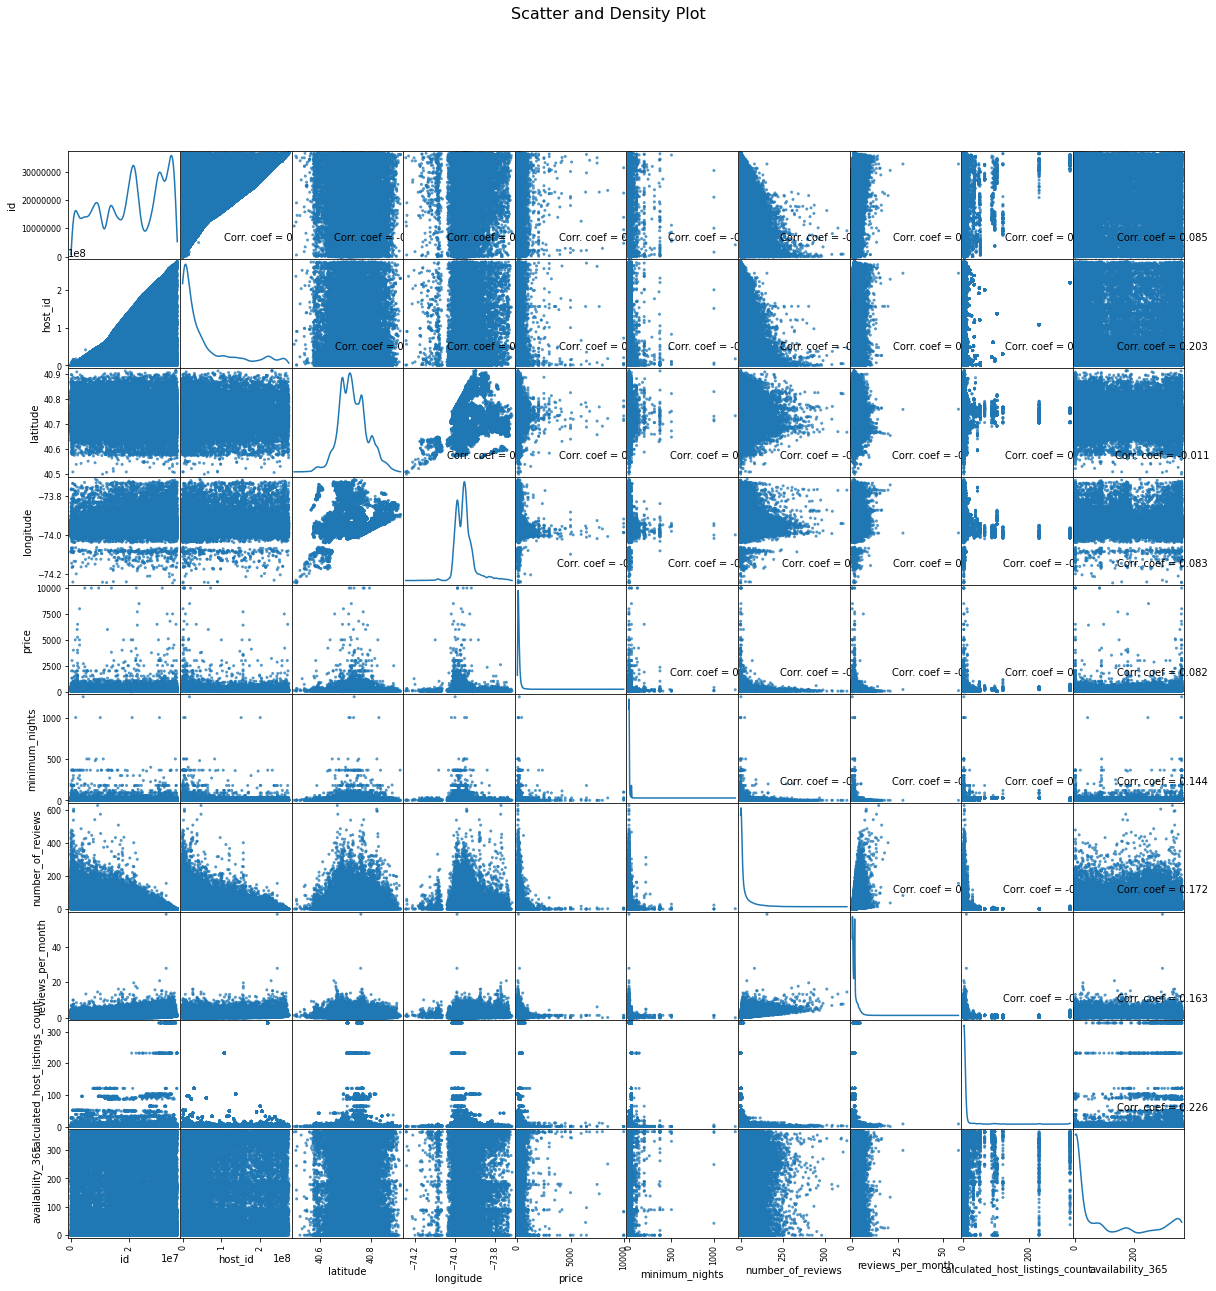

In [73]:
plotScatterMatrix(nyc_data_analysis, 20, 10)

Scatter matrix plots show the trend in the data by plotting numeric variables compactly. It contains all the pairwise scatter plots of the variables on a single page in a matrix format, allowing many relationships to be explored in one chart. 

##Save New File

In [ ]:
# save the data to a new csv file
datapath = '../data'
save_file(nyc_data_analysis, 'nyc_data_after_EDA.csv', datapath)

Directory ../data was created.
Writing file.  "../data/nyc_data_after_EDA.csv"


In [ ]:
!pip install -U kaleido

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     |████████████████████████████████| 79.9 MB 113 kB/s 


In [ ]:
!pip install plotly

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [ ]:
!pip install notebook ipywidgets

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     |████████████████████████████████| 1.6 MB 6.1 MB/s 


In [ ]:
!pip install jupyterlab ipywidgets

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     |████████████████████████████████| 8.8 MB 6.5 MB/s 
     |████████████████████████████████| 346 kB 50.2 MB/s 
     |████████████████████████████████| 423 kB 56.8 MB/s 
     |████████████████████████████████| 54 kB 3.0 MB/s 
     |████████████████████████████████| 9.8 MB 38.3 MB/s 
     |████████████████████████████████| 55 kB 4.0 MB/s 
     |████████████████████████████████| 273 kB 71.7 MB/s 
     |████████████████████████████████| 80 kB 10.5 MB/s 
     |████████████████████████████████| 133 kB 48.3 MB/s 
     |████████████████████████████████| 71 kB 387 kB/s 
     |████████████████████████████████| 107 kB 70.6 MB/s 
     |████████████████████████████████| 92 kB 972 kB/s 
     |████████████████████████████████| 439 kB 65.0 MB/s 
     |████████████████████████████████| 86 kB 5.7 MB/s 
  Attempting uninstall: traitlets
    Found existing installation: traitlets 5.1.1
    Uninstalling t